In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import librosa.display
import soundfile as sf
import IPython.display as ipd

print("librosa version:", librosa.__version__)
print("numpy version:", np.__version__)
print("pandas version:", pd.__version__)

librosa version: 0.11.0
numpy version: 2.4.6
pandas version: 2.2.3


In [ ]:
!git clone --depth 1 https://github.com/karolpiczak/ESC-50.git

Cloning into 'ESC-50'...
remote: Enumerating objects: 2018, done.
remote: Counting objects: 100% (2018/2018), done.
remote: Compressing objects: 100% (1798/1798), done.
remote: Total 2018 (delta 215), reused 2009 (delta 214), pack-reused 0 (from 0)
Receiving objects: 100% (2018/2018), 615.62 MiB | 38.74 MiB/s, done.
Resolving deltas: 100% (215/215), done.
Updating files: 100% (2011/2011), done.


In [ ]:
print(os.listdir("."))

['.config', 'ESC-50', 'sample_data']


In [ ]:
DATA_DIR = "ESC-50"

print("Top-level contents:")
print(os.listdir(DATA_DIR))

print("\nMeta folder:")
print(os.listdir(f"{DATA_DIR}/meta"))

audio_files = sorted(os.listdir(f"{DATA_DIR}/audio"))
print(f"\nNumber of audio files: {len(audio_files)}")
print("First 5 files:", audio_files[:5])

Top-level contents:
['audio', '.gitignore', 'esc50.gif', 'meta', '.circleci', 'requirements.txt', 'README.md', '.github', '.git', 'pytest.ini', 'LICENSE', 'tests']

Meta folder:
['esc50-human.xlsx', 'esc50.csv']

Number of audio files: 2000
First 5 files: ['1-100032-A-0.wav', '1-100038-A-14.wav', '1-100210-A-36.wav', '1-100210-B-36.wav', '1-101296-A-19.wav']


In [ ]:
meta = pd.read_csv(f"{DATA_DIR}/meta/esc50.csv")

print("Shape:", meta.shape)
meta.head(10)

Shape: (2000, 7)


,filename,fold,target,category,esc10,src_file,take
0,1-100032-A-0.wav,1,0,dog,True,100032,A
1,1-100038-A-14.wav,1,14,chirping_birds,False,100038,A
2,1-100210-A-36.wav,1,36,vacuum_cleaner,False,100210,A
3,1-100210-B-36.wav,1,36,vacuum_cleaner,False,100210,B
4,1-101296-A-19.wav,1,19,thunderstorm,False,101296,A
5,1-101296-B-19.wav,1,19,thunderstorm,False,101296,B
6,1-101336-A-30.wav,1,30,door_wood_knock,False,101336,A
7,1-101404-A-34.wav,1,34,can_opening,False,101404,A
8,1-103298-A-9.wav,1,9,crow,False,103298,A
9,1-103995-A-30.wav,1,30,door_wood_knock,False,103995,A


In [ ]:
classes = meta[["target", "category"]].drop_duplicates().sort_values("target")
print(classes.to_string(index=False))

 target         category
      0              dog
      1          rooster
      2              pig
      3              cow
      4             frog
      5              cat
      6              hen
      7          insects
      8            sheep
      9             crow
     10             rain
     11        sea_waves
     12   crackling_fire
     13         crickets
     14   chirping_birds
     15      water_drops
     16             wind
     17    pouring_water
     18     toilet_flush
     19     thunderstorm
     20      crying_baby
     21         sneezing
     22         clapping
     23        breathing
     24         coughing
     25        footsteps
     26         laughing
     27   brushing_teeth
     28          snoring
     29 drinking_sipping
     30  door_wood_knock
     31      mouse_click
     32  keyboard_typing
     33 door_wood_creaks
     34      can_opening
     35  washing_machine
     36   vacuum_cleaner
     37      clock_alarm
     38       clock_tick


In [ ]:
counts = meta["category"].value_counts()
print("Clips per class (min / max):", counts.min(), "/", counts.max())

print("\nClips per fold:")
print(meta["fold"].value_counts().sort_index())

Clips per class (min / max): 40 / 40

Clips per fold:
fold
1    400
2    400
3    400
4    400
5    400
Name: count, dtype: int64


In [ ]:
fold_class_table = pd.crosstab(meta["category"], meta["fold"])
print(fold_class_table.head(10))
print("\nMin clips of any class in any fold:", fold_class_table.values.min())
print("Max clips of any class in any fold:", fold_class_table.values.max())

fold            1  2  3  4  5
category                     
airplane        8  8  8  8  8
breathing       8  8  8  8  8
brushing_teeth  8  8  8  8  8
can_opening     8  8  8  8  8
car_horn        8  8  8  8  8
cat             8  8  8  8  8
chainsaw        8  8  8  8  8
chirping_birds  8  8  8  8  8
church_bells    8  8  8  8  8
clapping        8  8  8  8  8

Min clips of any class in any fold: 8
Max clips of any class in any fold: 8


In [ ]:
folds_per_source = meta.groupby("src_file")["fold"].nunique()

print("Unique source recordings:", folds_per_source.shape[0])
print("Sources appearing in more than one fold:", (folds_per_source > 1).sum())

Unique source recordings: 1524
Sources appearing in more than one fold: 4


In [ ]:
shortlist = ["crying_baby", "door_wood_knock", "glass_breaking", "siren",
             "car_horn", "dog", "footsteps", "clock_alarm"]

print(meta[meta["category"].isin(shortlist)]["category"].value_counts())

category
dog                40
door_wood_knock    40
clock_alarm        40
footsteps          40
car_horn           40
crying_baby        40
glass_breaking     40
siren              40
Name: count, dtype: int64


In [ ]:
leaky = folds_per_source[folds_per_source > 1].index
print(meta[meta["src_file"].isin(leaky)].sort_values(["src_file", "fold"])[
    ["filename", "fold", "category", "src_file", "take"]
].to_string(index=False))

         filename  fold    category  src_file take
2-131943-A-38.wav     2  clock_tick    131943    A
3-131943-A-37.wav     3 clock_alarm    131943    A
 2-134049-A-6.wav     2         hen    134049    A
 3-134049-A-1.wav     3     rooster    134049    A
4-209698-A-37.wav     4 clock_alarm    209698    A
5-209698-A-38.wav     5  clock_tick    209698    A
 4-234879-A-6.wav     4         hen    234879    A
 5-234879-A-1.wav     5     rooster    234879    A
 5-234879-B-1.wav     5     rooster    234879    B


In [ ]:
# Does any source appear in more than one fold WITHIN the same class?
check = meta.groupby(["src_file", "category"])["fold"].nunique()
print("Same source + same class in multiple folds:", (check > 1).sum())

Same source + same class in multiple folds: 0


In [ ]:
records = []
for fname in meta["filename"]:
    info = sf.info(f"{DATA_DIR}/audio/{fname}")
    records.append({
        "filename": fname,
        "sample_rate": info.samplerate,
        "channels": info.channels,
        "duration_sec": info.duration,
    })

audio_info = pd.DataFrame(records)
print("Sample rates:", audio_info["sample_rate"].unique())
print("Channels:", audio_info["channels"].unique())
print("Durations:", audio_info["duration_sec"].round(2).unique())

Sample rates: [44100]
Channels: [1]
Durations: [5.]


In [ ]:
row = meta[meta["category"] == "crying_baby"].iloc[0]
file_path = f"{DATA_DIR}/audio/{row['filename']}"
print("File:", row["filename"], "| Fold:", row["fold"])

y, sr = librosa.load(file_path, sr=None)

print("Sample rate:", sr)
print("Array shape:", y.shape)
print("Duration (s):", len(y) / sr)
print("Min / Max amplitude:", y.min(), "/", y.max())

ipd.Audio(y, rate=sr)

File: 1-187207-A-20.wav | Fold: 1
Sample rate: 44100
Array shape: (220500,)
Duration (s): 5.0
Min / Max amplitude: -0.8782959 / 0.94281006


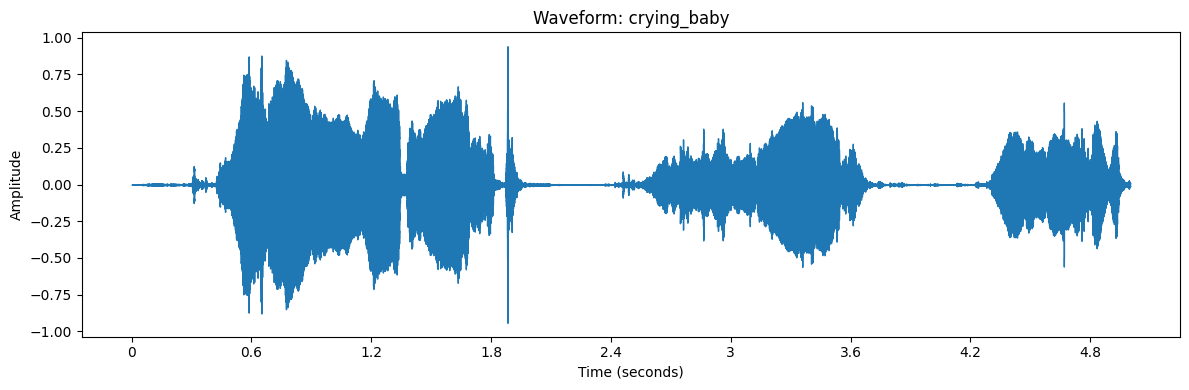

In [ ]:
plt.figure(figsize=(12, 4))
librosa.display.waveshow(y, sr=sr)
plt.title(f"Waveform: {row['category']}")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.tight_layout()
plt.show()

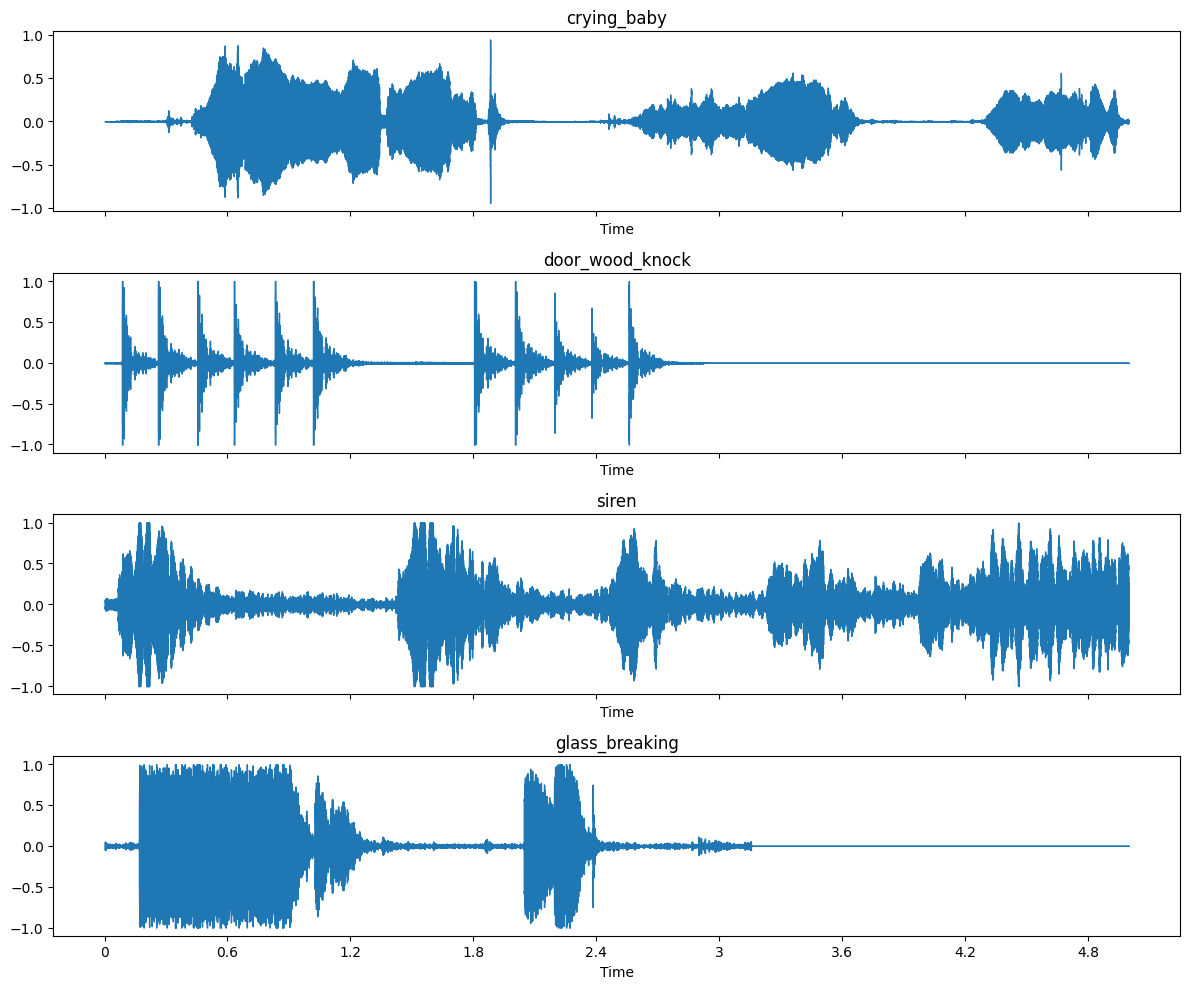

In [ ]:
categories_to_compare = ["crying_baby", "door_wood_knock", "siren", "glass_breaking"]

fig, axes = plt.subplots(len(categories_to_compare), 1, figsize=(12, 10), sharex=True)

for ax, cat in zip(axes, categories_to_compare):
    r = meta[meta["category"] == cat].iloc[0]
    y_c, sr_c = librosa.load(f"{DATA_DIR}/audio/{r['filename']}", sr=None)
    librosa.display.waveshow(y_c, sr=sr_c, ax=ax)
    ax.set_title(cat)

plt.tight_layout()
plt.show()

In [ ]:
for cat in categories_to_compare:
    r = meta[meta["category"] == cat].iloc[0]
    y_c, sr_c = librosa.load(f"{DATA_DIR}/audio/{r['filename']}", sr=None)
    print(cat)
    ipd.display(ipd.Audio(y_c, rate=sr_c))

crying_baby


door_wood_knock


siren


glass_breaking


# Phase 1 Summary: ESC-50 Dataset Exploration

- 2,000 clips, 50 classes, 40 clips per class, 5 folds of 400 clips
- Every class has exactly 8 clips in each fold
- Audio format: 44,100 Hz, mono, 5.0 seconds (220,500 samples per clip)
- 1,524 unique source recordings
- Official folds keep same-class clips from one source in one fold
  (verified: 0 violations)
- 4 sources appear in two folds under different classes
  (hen/rooster, clock_tick/clock_alarm). They are different sounds from
  the same file, so this is a negligible exception.
- ESC-50 has no doorbell, fire/smoke alarm, or phone ring class.
  Extra data collection is required before supporting them.
- Shortlist: crying_baby, door_wood_knock, glass_breaking, siren,
  car_horn, dog, clock_alarm, plus a background/other class
- License: CC BY-NC (check before any commercial use)